# ALS Patient Clustering Analysis

Exploratory unsupervised learning using anonymized ALS patient measurements.


## Project Overview
This project uses feature scaling, K-means clustering, silhouette scores, and PCA to explore patterns in anonymized ALS patient data.


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.environ["OMP_NUM_THREADS"] = "9"
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from IPython.display import display, HTML

# 1.Load the ALS dataset
display(HTML("<h3 style='font-weight:bold;'>Step 1: Load ALS Dataset</h3>"))
from pathlib import Path
data_path = Path("data/raw/als_data.csv")
if not data_path.exists():
    data_path = Path("../data/raw/als_data.csv")
df = pd.read_csv(data_path)
display(HTML("<b>First 5 Rows of the Dataset</b>"))
display(df.head())
display(HTML("<b>Dataset Structure and Data Types</b>"))
df.info()
display(HTML("<b>Summary Statistics</b>"))
display(df.describe())

,ID,Age_mean,Albumin_max,Albumin_median,Albumin_min,Albumin_range,ALSFRS_slope,ALSFRS_Total_max,ALSFRS_Total_median,ALSFRS_Total_min,...,Sodium_min,Sodium_range,SubjectID,trunk_max,trunk_median,trunk_min,trunk_range,Urine.Ph_max,Urine.Ph_median,Urine.Ph_min
0,1,65,57.0,40.5,38.0,0.066202,-0.965608,30,28.0,22,...,143.0,0.017422,533,8,7.0,7,0.002646,6.0,6.0,6.0
1,2,48,45.0,41.0,39.0,0.010453,-0.921717,37,33.0,21,...,136.0,0.010453,649,8,7.0,5,0.005386,7.0,5.0,5.0
2,3,38,50.0,47.0,45.0,0.008929,-0.914787,24,14.0,10,...,140.0,0.008929,1234,5,0.0,0,0.008929,6.0,5.0,5.0
3,4,63,47.0,44.0,41.0,0.012111,-0.598361,30,29.0,24,...,138.0,0.012469,2492,5,5.0,3,0.004988,7.0,6.0,5.0
4,5,63,47.0,45.5,42.0,0.008292,-0.444039,32,27.5,20,...,138.0,0.008292,2956,6,4.0,1,0.008489,6.0,5.0,5.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2223 entries, 0 to 2222
Columns: 101 entries, ID to Urine.Ph_min
dtypes: float64(75), int64(26)
memory usage: 1.7 MB


,ID,Age_mean,Albumin_max,Albumin_median,Albumin_min,Albumin_range,ALSFRS_slope,ALSFRS_Total_max,ALSFRS_Total_median,ALSFRS_Total_min,...,Sodium_min,Sodium_range,SubjectID,trunk_max,trunk_median,trunk_min,trunk_range,Urine.Ph_max,Urine.Ph_median,Urine.Ph_min
count,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,...,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000,2223.000000
mean,1214.874944,54.550157,47.011134,43.952542,40.766347,0.013779,-0.728274,31.692308,27.104926,19.877193,...,136.755061,0.015000,498880.290148,6.203779,4.893387,2.955915,0.007136,6.820450,5.710639,5.183221
std,696.678300,11.396546,3.233980,2.654804,3.193087,0.009567,0.622329,5.314228,6.633643,8.583509,...,2.715247,0.009283,289923.528450,1.747660,2.146076,2.358095,0.004503,0.932141,0.625039,0.437222
min,1.000000,18.000000,37.000000,34.500000,24.000000,0.000000,-4.345238,11.000000,2.500000,0.000000,...,112.000000,0.000000,533.000000,0.000000,0.000000,0.000000,0.000000,5.000000,5.000000,5.000000
25%,614.500000,47.000000,45.000000,42.000000,39.000000,0.009042,-1.086310,29.000000,23.000000,14.000000,...,135.000000,0.010582,240825.500000,5.000000,3.000000,1.000000,0.003643,6.000000,5.000000,5.000000
50%,1213.000000,55.000000,47.000000,44.000000,41.000000,0.012111,-0.620748,33.000000,28.000000,20.000000,...,137.000000,0.013123,496835.000000,7.000000,5.000000,3.000000,0.006920,7.000000,6.000000,5.000000
75%,1815.500000,63.000000,49.000000,46.000000,43.000000,0.015873,-0.283832,36.000000,32.000000,27.000000,...,138.000000,0.017278,750300.500000,8.000000,6.500000,5.000000,0.009639,7.000000,6.000000,5.000000
max,2424.000000,81.000000,70.300000,51.100000,49.000000,0.243902,1.207011,40.000000,40.000000,40.000000,...,145.000000,0.142857,999482.000000,8.000000,8.000000,8.000000,0.042017,9.000000,9.000000,8.000000


#### **Interpretation:**
-  The dataset loads successfully, and each row represents an observation associated with an ALS patient.
-  The presence of ALS related clinical measurements and statistical summaries (mean, min, max, standard deviation) indicates that the dataset captures meaningful disease information.
- All variables are numeric except SubjectID.
- No major missing values are observed.

In [2]:
# 2.Remove any data that is not relevant to the patient’s ALS condition
"""
Clustering aims to group patients based on similarities in ALS related clinical characteristics. SubjectID is a unique identifier and does not
not contain clinical meaning. Including it would distort distance calculations and bias cluster formation. 
"""
display(HTML("<h3 style='font-weight:bold;'>Step 2: Remove non-relevant variables</h3>"))
columns_to_drop = ['SubjectID']
df_clean = df.drop(columns=columns_to_drop)
print("Remaining columns used for clustering:")
display(df_clean.columns.tolist())
display(HTML(f"<b>Dataset shape after removal:</b> {df_clean.shape}")) 
display(HTML("<b>First 5 Rows of the cleaned Dataset</b>"))
display(df_clean.head())

Remaining columns used for clustering:


['ID',
 'Age_mean',
 'Albumin_max',
 'Albumin_median',
 'Albumin_min',
 'Albumin_range',
 'ALSFRS_slope',
 'ALSFRS_Total_max',
 'ALSFRS_Total_median',
 'ALSFRS_Total_min',
 'ALSFRS_Total_range',
 'ALT.SGPT._max',
 'ALT.SGPT._median',
 'ALT.SGPT._min',
 'ALT.SGPT._range',
 'AST.SGOT._max',
 'AST.SGOT._median',
 'AST.SGOT._min',
 'AST.SGOT._range',
 'Bicarbonate_max',
 'Bicarbonate_median',
 'Bicarbonate_min',
 'Bicarbonate_range',
 'Blood.Urea.Nitrogen..BUN._max',
 'Blood.Urea.Nitrogen..BUN._median',
 'Blood.Urea.Nitrogen..BUN._min',
 'Blood.Urea.Nitrogen..BUN._range',
 'bp_diastolic_max',
 'bp_diastolic_median',
 'bp_diastolic_min',
 'bp_diastolic_range',
 'bp_systolic_max',
 'bp_systolic_median',
 'bp_systolic_min',
 'bp_systolic_range',
 'Calcium_max',
 'Calcium_median',
 'Calcium_min',
 'Calcium_range',
 'Chloride_max',
 'Chloride_median',
 'Chloride_min',
 'Chloride_range',
 'Creatinine_max',
 'Creatinine_median',
 'Creatinine_min',
 'Creatinine_range',
 'Gender_mean',
 'Glucose_ma

,ID,Age_mean,Albumin_max,Albumin_median,Albumin_min,Albumin_range,ALSFRS_slope,ALSFRS_Total_max,ALSFRS_Total_median,ALSFRS_Total_min,...,Sodium_median,Sodium_min,Sodium_range,trunk_max,trunk_median,trunk_min,trunk_range,Urine.Ph_max,Urine.Ph_median,Urine.Ph_min
0,1,65,57.0,40.5,38.0,0.066202,-0.965608,30,28.0,22,...,145.5,143.0,0.017422,8,7.0,7,0.002646,6.0,6.0,6.0
1,2,48,45.0,41.0,39.0,0.010453,-0.921717,37,33.0,21,...,138.0,136.0,0.010453,8,7.0,5,0.005386,7.0,5.0,5.0
2,3,38,50.0,47.0,45.0,0.008929,-0.914787,24,14.0,10,...,143.0,140.0,0.008929,5,0.0,0,0.008929,6.0,5.0,5.0
3,4,63,47.0,44.0,41.0,0.012111,-0.598361,30,29.0,24,...,139.0,138.0,0.012469,5,5.0,3,0.004988,7.0,6.0,5.0
4,5,63,47.0,45.5,42.0,0.008292,-0.444039,32,27.5,20,...,140.0,138.0,0.008292,6,4.0,1,0.008489,6.0,5.0,5.0


#### **Interpretation:**
- After removing SubjectID, all remaining variables represent clinical or statistical measurements relevant to ALS. The dataset is now suitable
for numerical analysis and clustering.

In [3]:
# 3. Apply a standard scalar to the data
display(HTML("<h3><b>Step 3: Standardize the data</b></h3>"))
"""
K-means clustering relies on Euclidean distance. Variables measured on larger numeric scales would dominate distance calculations if the data
were left unscaled. Standardization ensures each feature contributes equally to the clustering process.
"""
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_clean)
scaled_df = pd.DataFrame(scaled_data, columns=df_clean.columns)
display(HTML("<b>First 5 Rows of Standardized Data</b>"))
display(scaled_df.head())
display(HTML("<b>Feature Means After Standardization</b>"))
display(scaled_df.mean().to_frame("Mean"))
display(HTML("<b>Feature Standard Deviations After Standardization</b>"))
display(scaled_df.std().to_frame("Std Dev"))

,ID,Age_mean,Albumin_max,Albumin_median,Albumin_min,Albumin_range,ALSFRS_slope,ALSFRS_Total_max,ALSFRS_Total_median,ALSFRS_Total_min,...,Sodium_median,Sodium_min,Sodium_range,trunk_max,trunk_median,trunk_min,trunk_range,Urine.Ph_max,Urine.Ph_median,Urine.Ph_min
0,-1.742767,0.917137,3.089417,-1.300781,-0.866550,5.480929,-0.381450,-0.318520,0.134960,0.247368,...,2.992342,2.300470,0.260968,1.028018,0.981832,1.715365,-0.997420,-0.880376,0.463054,1.868532
1,-1.741331,-0.574879,-0.622016,-1.112401,-0.553303,-0.347725,-0.310907,0.998995,0.888863,0.130839,...,-1.198812,-0.278144,-0.489913,1.028018,0.981832,0.867032,-0.388669,0.192665,-1.137208,-0.419151
2,-1.739896,-1.452535,0.924415,1.148162,1.326179,-0.507103,-0.299769,-1.447819,-1.975969,-1.150976,...,1.595291,1.195350,-0.654169,-0.688950,-2.280669,-1.253800,0.398249,-0.880376,-1.137208,-0.419151
3,-1.738460,0.741606,-0.003443,0.017880,0.073191,-0.174361,0.208801,-0.318520,0.285741,0.480425,...,-0.639992,0.458603,-0.272701,-0.688950,0.049689,0.018699,-0.477181,0.192665,0.463054,-0.419151
4,-1.737024,0.741606,-0.003443,0.583021,0.386438,-0.573670,0.456831,0.057913,0.059570,0.014311,...,-0.081171,0.458603,-0.722774,-0.116627,-0.416383,-0.829634,0.300598,-0.880376,-1.137208,-0.419151


,Mean
ID,0.000000e+00
Age_mean,-1.749987e-16
Albumin_max,-4.299055e-16
Albumin_median,-5.369824e-16
Albumin_min,-2.660939e-16
...,...
trunk_min,6.872096e-17
trunk_range,1.246566e-16
Urine.Ph_max,1.016431e-15
Urine.Ph_median,1.150676e-16


,Std Dev
ID,1.000225
Age_mean,1.000225
Albumin_max,1.000225
Albumin_median,1.000225
Albumin_min,1.000225
...,...
trunk_min,1.000225
trunk_range,1.000225
Urine.Ph_max,1.000225
Urine.Ph_median,1.000225


#### **Interpretation:**
- After scaling, all features now have a mean of zero and a standard deviation of one. This confirms that differences in scale have been standardized(removed), making the data appropriate for K-means clustering.

In [4]:
# 4. Create a plot of the cluster silhouette score versus the number of clusters in a K-means cluster
display(HTML("<h3><b>Step 4: Compute silhouette scores</b></h3>"))
"""
Silhouette score evaluates how well data points fit within the assigned clusters.
"""
silhouette_scores = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_df)
    score = silhouette_score(scaled_df, labels)
    silhouette_scores.append(score)
silhouette_df = pd.DataFrame({
    "Number of Clusters (k)": list(k_range),
    "Silhouette Score": silhouette_scores
})
display(HTML("<b>Silhouette Scores for Different Cluster Sizes</b>"))
display(silhouette_df)

,Number of Clusters (k),Silhouette Score
0,2,0.077764
1,3,0.067452
2,4,0.068727
3,5,0.056065
4,6,0.062685
5,7,0.066004
6,8,0.052912
7,9,0.050947
8,10,0.050050


#### **Interpretation:**
- Silhouette scores measure how well each observation fits within its assigned cluster. Higher scores indicate better separation.
- The silhouette score is a valuable metric for evaluating the quality of clustering results. In the case of the ALS dataset, the silhouette score for k = 2 indicates that this number of clusters provides the most coherent grouping, as it yields the highest silhouette score (0.078).
- This suggests that the two cluster solution effectively separates the data into distinct groups with clear boundaries.
- The silhouette score ranges from -1 to 1, a higher value indicates better separation between clusters. Therefore, the two cluster solution is likely to be the most effective for clustering the ALS dataset.

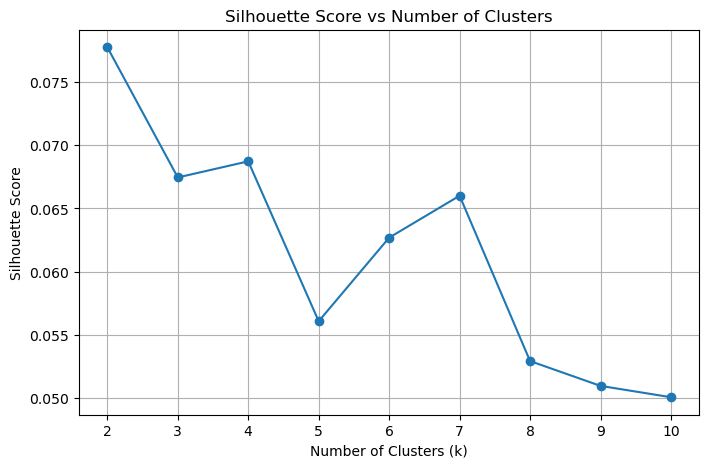

In [5]:
# 4.1 Create a plot of the cluster silhouette score versus the number of clusters in a K-means cluster
display(HTML("<h3><b>Step 4.1: Plot silhouette score vs number of clusters</b></h3>"))
"""
Visualizing silhouette scores allows to clearly see where cluster quality peaks or stabilizes
"""
plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs Number of Clusters")
plt.grid(True)
plt.show()

#### **Interpretation:**
- The Silhouette analysis suggests 2 clusters as optimal, where the score peaks at approximately 0.078, suggesting the clearest separation.
- A secondary peak occurs at 7 cluster (k=7) for more detailed grouping.
- Scores are lowest at 5 cluster(k=5), indicating poor separation, and generally decline beyond 7, showing diminishing returns.
- Overall, the low Silhouette values (0.05–0.08) indicate that the clusters overlap considerably and are not strongly distinct.

In [6]:
# 5. Fit a K-means model to the data with the optimal number of clusters chosen in part (4).
display(HTML("<h3><b>Step 5: Fit Final K-Means Model</b></h3>"))
"""
The final K-means model assigns each patient to one of the two clusters, allowing subgroup-level analysis of ALS characteristics.
"""
optimal_k = 2
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(scaled_df)
scaled_df['Cluster'] = clusters
display(HTML("<b>Number of Observations per Cluster</b>"))
display(scaled_df['Cluster'].value_counts().to_frame("Count"))

,Count
Cluster,
0,1113
1,1110


#### **Interpretation:**
- Each patient record now includes a cluster label, enabling comparison across ALS patient subgroups.
- The distribution of observations across clusters showed that both groups contained a substantial number of patients, supporting the stability of the two cluster solution.

In [7]:
# 6. Fit a PCA transformation with two features to the scaled data..
display(HTML("<h3><b>Step 6: Fit a PCA transformation with two features.</b></h3>"))
"""
The dataset contains many variables, making visualization difficult. PCA compresses the data into two components while preserving the most
important variance for visual inspection.
"""
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_df.drop(columns='Cluster'))
explained_variance = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance Ratio": pca.explained_variance_ratio_
})
display(HTML("<b>Explained Variance by PCA Components</b>"))
display(explained_variance)
display(HTML(
    f"<b>Total Variance Explained:</b> "
    f"{np.sum(pca.explained_variance_ratio_):.2f}"
))
pca_df = pd.DataFrame(
    pca_data,
    columns=['Principal Component 1', 'Principal Component 2']
)
pca_df['Cluster'] = clusters

,Principal Component,Explained Variance Ratio
0,PC1,0.112175
1,PC2,0.063822


#### **Interpretation:**
- The total variance explained by the model is low, it suggests the ALS data is complex and high dimensional, with variations spread across many variables rather than dominated by a few.
- The first two principal components capture most of the variability in ALS clinical measurements, making them suitable for visualization.

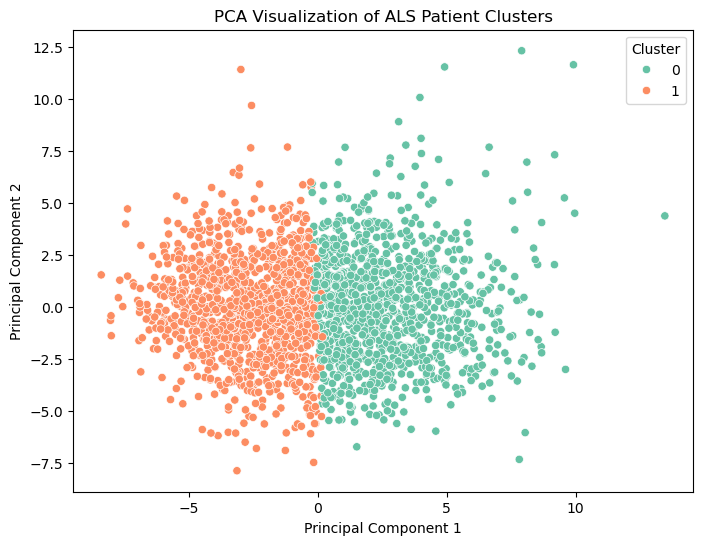

In [8]:
# 7. Make a scatterplot the PCA transformed data coloring each point by its cluster value.
display(HTML("<h3><b>Step 7: PCA Cluster Visualization</b></h3>"))
"""
Visual confirmation helps validate whether numerical clustering results reflect meaningful separation in reduced dimensions.
"""
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_df,
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',
    palette='Set2'
)
plt.title("PCA Visualization of ALS Patient Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

#### **Interpretation:**
- The clusters are not completely distinct and overlap with each other. This is expected because ALS progresses differently across patients, meaning disease patterns change gradually rather than falling into clear cut groups.

### **Summary of Findings:**
- This analysis used K-means clustering to explore patterns within ALS patient data by grouping individuals based on the clinical and functional measurements. Prior to clustering, careful preprocessing was performed to ensure that only meaningful ALS-related variables were included, while non-informative identifiers were removed. This step was essential to ensure that the resulting clusters reflected true clinical similarities rather than arbitrary labels.
- Since the variables were measured on different scales, the data were standardized so that each feature contributed equally to the clustering process. Silhouette analysis was used to compare different clustering solutions and determine the most appropriate number of clusters. Based on these results, a two cluster solution was selected as it offered a practical balance between group separation and interpretability.
- To further assess the structure of the clusters, Principal Component Analysis (PCA) was used to reduce the data to two dimensions for visualization. The PCA plot revealed meaningful grouping of patients, with clusters showing partial separation and some overlap. This overlap is expected given the heterogeneous nature of ALS, where disease progression and symptom severity vary continuously across patients rather than forming sharply defined categories.
- Overall, the results demonstrate that unsupervised learning techniques such as K-means can uncover underlying structure in complex medical datasets without prior labeling. The identified clusters suggest the presence of distinct but overlapping patient profiles that may correspond to differences in disease severity, progression patterns, or functional status.These findings provide a strong foundation for future work, including clinical interpretation of clusters, longitudinal progression analysis, and the development of more personalized approaches to ALS research and care.

### **Conclusion:**
This shows that K-means clustering is a useful approach for examining patterns in ALS patient data when the data are properly cleaned and standardized. The analysis identified a two cluster solution as the most stable option according to silhouette scores, although the low score values indicate that the clusters are not clearly separated. The PCA visualization reinforces this result by displaying only partial separation and noticeable overlap between clusters, which reflects the diverse and complex nature of ALS progression. Overall, the results suggest that ALS patient profiles exist along a gradual spectrum rather than as clearly defined groups, and the clustering outcomes should be considered exploratory and serve as a starting point for more in depth future research.